# **Recurrent Neural Network (RNN)**

## Deskripsi Proyek

Proyek ini bertujuan untuk mengklasifikasikan emosi pada ulasan pelanggan berbahasa Indonesia menggunakan metode Recurrent Neural Network (RNN). Dataset yang digunakan adalah PRDECT-ID dengan lima kategori emosi, yaitu anger, fear, happy, love, dan sadness.

Model dibangun menggunakan Simple RNN dengan bantuan pretrained embedding FastText Bahasa Indonesia. Tahapan yang dilakukan meliputi preprocessing teks, tokenisasi, training model, evaluasi performa, dan pengujian prediksi terhadap ulasan baru.

## Import library

Memuat library untuk pengolahan data, preprocessing teks, pembuatan model RNN, evaluasi, dan visualisasi.

In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU tersedia: []


## Upload dan membaca dataset

Unduh file CSV dari halaman Kaggle, lalu upload file CSV tersebut ke Colab saat diminta. Kode mencoba beberapa encoding agar file CSV tetap dapat dibaca.

In [ ]:
uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Tidak ada file CSV yang di-upload. Silakan upload dataset PRDECT-ID.")

file_path = csv_files[0]

try:
    df = pd.read_csv(file_path)
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin-1")

# Rapikan nama kolom dari spasi di awal/akhir
df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)
print("\nDaftar kolom:")
print(df.columns.tolist())
display(df.head())

Saving PRDECT-ID Dataset.csv to PRDECT-ID Dataset.csv
Ukuran dataset: (5400, 11)

Daftar kolom:
['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging...,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing ...",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ram...",Positive,Happy
3,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,bagus sesuai harapan penjual nya juga ramah. t...,Positive,Happy
4,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",Positive,Happy


## Menentukan kolom teks dan label

Dataset PRDECT-ID menyediakan ulasan pelanggan dan label emosi. Program memeriksa keberadaan kolom agar kesalahan penamaan dapat diketahui sejak awal.

In [ ]:
TEXT_COL = "Customer Review"
TARGET_COL = "Emotion"

if TEXT_COL not in df.columns or TARGET_COL not in df.columns:
    raise ValueError(
        f"Kolom yang dibutuhkan tidak ditemukan. Kolom tersedia: {df.columns.tolist()}\n"
        f"Pastikan terdapat kolom '{TEXT_COL}' dan '{TARGET_COL}'."
    )

data = df[[TEXT_COL, TARGET_COL]].copy()
data = data.dropna(subset=[TEXT_COL, TARGET_COL])
data[TEXT_COL] = data[TEXT_COL].astype(str)
data[TARGET_COL] = data[TARGET_COL].astype(str).str.strip().str.lower()

# Hapus baris yang teksnya kosong setelah dibersihkan dari spasi
data = data[data[TEXT_COL].str.strip() != ""]
data = data.drop_duplicates(subset=[TEXT_COL, TARGET_COL]).reset_index(drop=True)

print("Jumlah data setelah pembersihan awal:", len(data))
print("\nDistribusi label:")
print(data[TARGET_COL].value_counts())

Jumlah data setelah pembersihan awal: 5330

Distribusi label:
Emotion
happy      1754
sadness    1185
fear        907
love        802
anger       682
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

Melihat distribusi kelas emosi. Informasi ini penting untuk mengetahui apakah dataset seimbang atau memiliki kelas yang jumlah datanya jauh lebih sedikit.

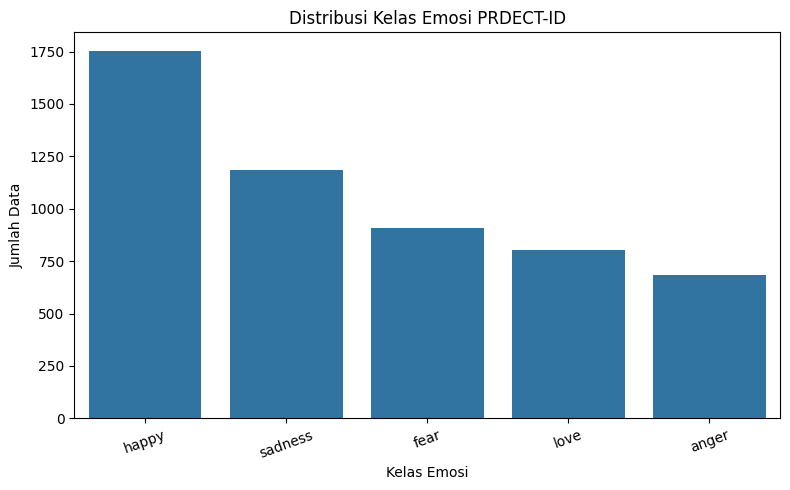


Statistik panjang ulasan (jumlah karakter):
count    5330.000000
mean      104.092683
std        97.693594
min         3.000000
25%        45.000000
50%        78.000000
75%       128.000000
max      1058.000000
Name: Customer Review, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x=TARGET_COL, order=data[TARGET_COL].value_counts().index)
plt.title("Distribusi Kelas Emosi PRDECT-ID")
plt.xlabel("Kelas Emosi")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("\nStatistik panjang ulasan (jumlah karakter):")
print(data[TEXT_COL].str.len().describe())

## Preprocessing teks

Preprocessing dilakukan secara ringan: mengubah huruf menjadi lowercase, menghapus URL, mention, karakter selain huruf/angka, dan spasi berlebih. Kata negasi seperti *tidak*, *bukan*, dan *belum* tetap dipertahankan karena dapat mengubah makna emosi.

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)  # URL
    text = re.sub(r"@\\w+", " ", text)                       # mention
    text = re.sub(r"[^a-z0-9\\s]", " ", text)                 # tanda baca/simbol
    text = re.sub(r"\\s+", " ", text).strip()                # spasi berlebih
    return text

data["clean_review"] = data[TEXT_COL].apply(clean_text)
data = data[data["clean_review"].str.len() > 0].reset_index(drop=True)

display(data[[TEXT_COL, "clean_review", TARGET_COL]].head())
print("Jumlah data setelah preprocessing:", len(data))

,Customer Review,clean_review,Emotion
0,Alhamdulillah berfungsi dengan baik. Packaging...,alhamdulillah berfungsi dengan baik packaging...,happy
1,"barang bagus dan respon cepat, harga bersaing ...",barang bagus dan respon cepat harga bersaing ...,happy
2,"barang bagus, berfungsi dengan baik, seler ram...",barang bagus berfungsi dengan baik seler ram...,happy
3,bagus sesuai harapan penjual nya juga ramah. t...,bagus sesuai harapan penjual nya juga ramah t...,happy
4,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",barang bagus pengemasan aman dapat berfungsi...,happy


Jumlah data setelah preprocessing: 5330


## Encoding label dan pembagian data

Label emosi diubah menjadi angka. Data dibagi secara stratified menjadi 70% training, 15% validation, dan 15% testing. Stratified split menjaga proporsi kelas pada setiap subset.

In [ ]:
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(data[TARGET_COL])
X_all = data["clean_review"].values

class_names = label_encoder.classes_
num_classes = len(class_names)

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=SEED, stratify=y_all
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Kelas:", list(class_names))
print(f"Training   : {len(X_train_text)} data")
print(f"Validation : {len(X_val_text)} data")
print(f"Testing    : {len(X_test_text)} data")

Kelas: ['anger', 'fear', 'happy', 'love', 'sadness']
Training   : 3731 data
Validation : 799 data
Testing    : 800 data


## Tokenisasi dan padding

Tokenizer hanya di-*fit* menggunakan data training untuk menghindari kebocoran informasi dari data validation/testing. Setiap ulasan diubah menjadi urutan angka dan disamakan panjangnya dengan padding.

In [ ]:
# Konfigurasi tokenisasi
MAX_WORDS = 30000
MAX_LEN = 50
OOV_TOKEN = "<OOV>"

# Tokenizer hanya belajar dari data training
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token=OOV_TOKEN
)

tokenizer.fit_on_texts(X_train_text)

# Mengubah teks menjadi sequence
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

# Padding (ubah ke "pre" agar kata-kata asli berada di akhir urutan dan tidak dilupakan SimpleRNN)
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="post"
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="post"
)

# Ukuran vocabulary
vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary Size:", vocab_size)
print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Vocabulary Size: 7245
Training Shape: (3731, 50)
Validation Shape: (799, 50)
Testing Shape: (800, 50)


## Mengatasi ketidakseimbangan kelas

Bobot kelas dihitung dari data training saja. Bobot ini membantu model agar tidak terlalu berfokus pada kelas yang jumlah datanya dominan.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

# Menghitung bobot kelas seimbang
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Menggunakan akar kuadrat agar bobot lebih moderat
weights = np.sqrt(weights)

# Normalisasi agar rata-rata bobot = 1
weights = weights / np.mean(weights)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

# Dorong sedikit bobot kelas 'anger' agar tidak kalah dari 'sadness'
anger_idx = int(label_encoder.transform(["anger"])[0])
class_weights[anger_idx] = class_weights[anger_idx] * 1.2

print("Class Weights:")
for cls, weight in class_weights.items():
    print(f"{label_encoder.inverse_transform([cls])[0]}: {weight:.4f}")

Class Weights:
anger: 1.4388
fear: 1.0392
happy: 0.7473
love: 1.1056
sadness: 0.9089


## Pre-trained Embedding FastText

In [ ]:
import os
import numpy as np

# Unduh FastText Bahasa Indonesia berukuran ringan
if not os.path.exists("cc.id.300.vec.gz"):
    !wget -q https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz
    !gunzip -f cc.id.300.vec.gz

EMBEDDING_DIM = 300
embeddings_index = {}

with open("cc.id.300.vec", encoding="utf-8", errors="ignore") as f:
    next(f)  # lewati baris header
    for line in f:
        values = line.rstrip().split(" ")
        word = values[0]
        coefs = np.asarray(values[1:], dtype="float32")
        embeddings_index[word] = coefs

embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM))
for word, i in tokenizer.word_index.items():
    if i < vocab_size:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

print("Embedding matrix siap:", embedding_matrix.shape)

Embedding matrix siap: (7245, 300)


## Membangun model Simple RNN

Arsitektur terdiri dari Embedding untuk merepresentasikan kata sebagai vektor, satu layer `SimpleRNN` untuk mempelajari urutan kata, Dropout untuk mengurangi overfitting, dan Dense Softmax untuk memprediksi lima kelas emosi.

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN,
    GlobalMaxPooling1D, GlobalAveragePooling1D,
    Concatenate, Dropout, Dense, SpatialDropout1D
)
from tensorflow.keras.optimizers import Adam

inputs = Input(shape=(MAX_LEN,))

# Gunakan bobot FastText (trainable=True agar tetap beradaptasi dengan bahasa e-commerce)
x = Embedding(
    input_dim=vocab_size,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],
    trainable=True
)(inputs)

x = SpatialDropout1D(0.2)(x)

# Tetap SimpleRNN murni 1 arah
rnn_out = SimpleRNN(64, activation="tanh", return_sequences=True)(x)

# Gabungkan rata-rata konteks kalimat & kata kunci emosi terkuat
avg_pool = GlobalAveragePooling1D()(rnn_out)
max_pool = GlobalMaxPooling1D()(rnn_out)
conc = Concatenate()([avg_pool, max_pool])

x = Dropout(0.4)(conc)
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)
outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=0.001, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 50, 300)   │  2,173,500 │ input_layer_8[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_7 │ (None, 50, 300)   │          0 │ embedding_9[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_9        │ (None, 50, 64)    │     23,360 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ simple_rnn_9[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ simple_rnn_9[0][… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 128)       │          0 │ concatenate_2[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 64)        │      8,256 │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 64)        │          0 │ dense_18[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 5)         │        325 │ dropout_19[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,205,441 (8.41 MB)

 Trainable params: 2,205,441 (8.41 MB)

 Non-trainable params: 0 (0.00 B)

## Training model

Model dilatih maksimal 30 epoch. `EarlyStopping` menghentikan training jika validation loss tidak membaik, sedangkan `ReduceLROnPlateau` menurunkan learning rate ketika proses belajar mulai stagnan.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

EPOCHS = 30
BATCH_SIZE = 32

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    shuffle=True
)

Epoch 1/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.3184 - loss: 1.5310 - val_accuracy: 0.4343 - val_loss: 1.3534 - learning_rate: 0.0010
Epoch 2/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.4556 - loss: 1.2293 - val_accuracy: 0.4793 - val_loss: 1.0547 - learning_rate: 0.0010
Epoch 3/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.4940 - loss: 1.0355 - val_accuracy: 0.5094 - val_loss: 0.9878 - learning_rate: 0.0010
Epoch 4/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.5352 - loss: 0.9487 - val_accuracy: 0.5907 - val_loss: 0.9553 - learning_rate: 0.0010
Epoch 5/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.6315 - loss: 0.8450 - val_accuracy: 0.6058 - val_loss: 0.9154 - learning_rate: 0.0010
Epoch 6/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6955 - loss: 0.7191 - val_accuracy: 0.6233 - val_loss: 0.8937 - learning_rate: 0.0010
Epoch 7/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 14s 73ms/step - accuracy: 0.7604 - loss: 0

## Visualisasi hasil training

Grafik accuracy dan loss digunakan untuk melihat perkembangan model pada data training dan validation, serta indikasi overfitting.

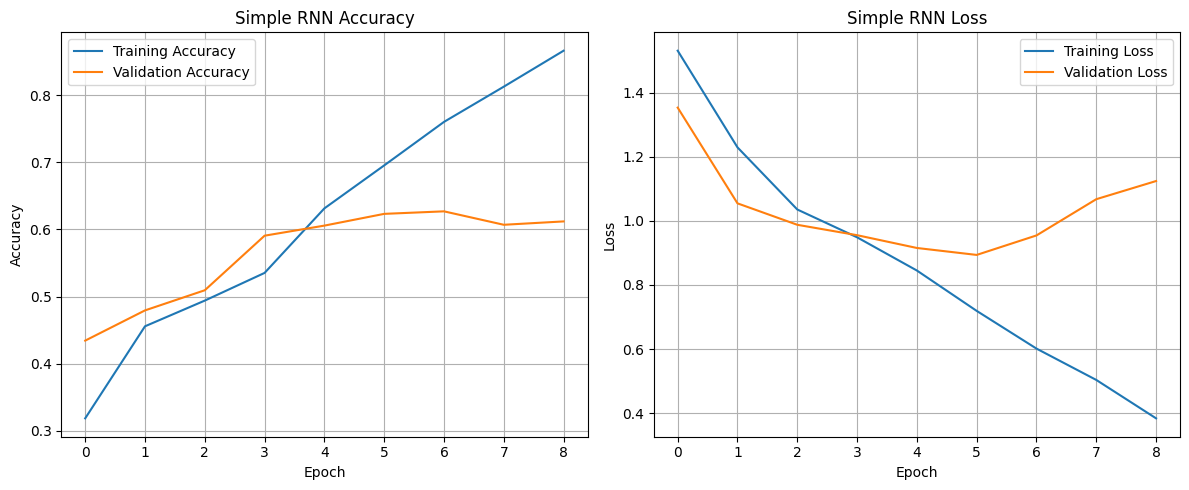

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Simple RNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Evaluasi pada data testing

Data testing tidak digunakan saat training maupun pemilihan model. Evaluasi melaporkan accuracy, macro precision, macro recall, dan macro F1-score. Macro average memberi bobot yang sama pada setiap kelas sehingga lebih informatif ketika distribusi kelas tidak seimbang.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Prediksi data testing
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

# Menghitung metrik
test_loss = model.evaluate(X_test, y_test, verbose=0)[0]

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("===== HASIL EVALUASI SIMPLE RNN =====")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Accuracy        : {accuracy:.4f}")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"Macro F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
===== HASIL EVALUASI SIMPLE RNN =====
Test Loss       : 0.8954
Accuracy        : 0.5825
Precision       : 0.5488
Recall          : 0.5357
Macro F1-Score  : 0.5400

Classification Report:
              precision    recall  f1-score   support

       anger       0.42      0.43      0.43       102
        fear       0.37      0.42      0.39       136
       happy       0.73      0.79      0.76       263
        love       0.60      0.48      0.53       121
     sadness       0.63      0.56      0.59       178

    accuracy                           0.58       800
   macro avg       0.55      0.54      0.54       800
weighted avg       0.59      0.58      0.58       800



## Ringkasan Hasil Model

Model Simple RNN memperoleh accuracy sebesar 58,25% dan Macro F1-Score sebesar 54,00% pada data testing.

Model memiliki performa terbaik dalam mengklasifikasikan emosi happy, sedangkan beberapa kelas lainnya masih memiliki tingkat kesalahan prediksi yang cukup tinggi. Hasil ini menunjukkan bahwa model masih dapat dikembangkan lebih lanjut, terutama dalam membedakan emosi yang memiliki karakteristik teks serupa.

##  Confusion Matrix

Confusion matrix memperlihatkan jumlah prediksi benar dan salah untuk setiap kelas emosi. Nilai diagonal menunjukkan prediksi yang benar.

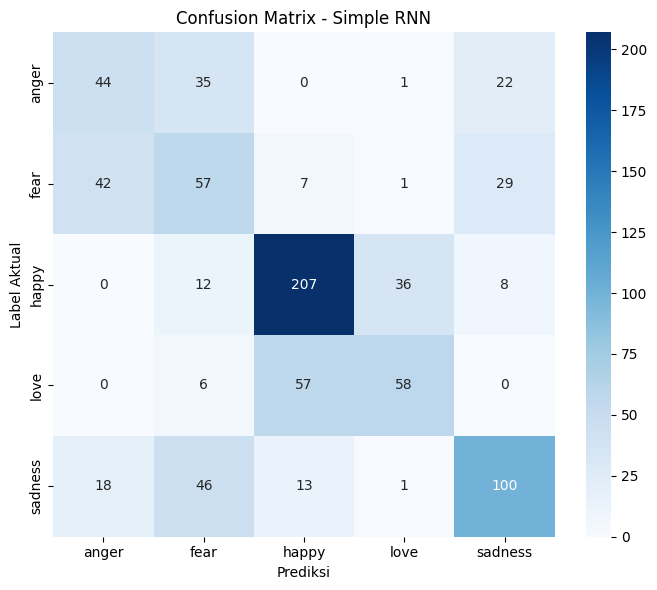

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Simple RNN")
plt.xlabel("Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

## Menyimpan model dan artefak preprocessing

Model, tokenizer, label encoder, dan konfigurasi disimpan agar dapat digunakan kembali. File hasil dapat diunduh dari Colab.

In [ ]:
import pickle
import json

model.save("simple_rnn_emotion.keras")

with open("tokenizer_rnn.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("label_encoder_rnn.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

metrics = {
    "model": "Simple RNN",
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
    "class_names": [str(x) for x in class_names],
    "max_words": MAX_WORDS,
    "max_len": MAX_LEN,
    "seed": SEED
}

with open("rnn_evaluation.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Model dan artefak preprocessing berhasil disimpan.")

Model dan artefak preprocessing berhasil disimpan.


## Uji prediksi ulasan baru

Masukkan ulasan baru untuk melihat kelas emosi yang diprediksi oleh model.

In [ ]:
def predict_emotion(review):
    cleaned = clean_text(review)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(sequence, maxlen=MAX_LEN, padding="post", truncating="post")
    probabilities = model.predict(padded, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    return class_names[predicted_index], float(probabilities[predicted_index])

contoh_ulasan = "Barangnya bagus sekali, saya sangat suka dan puas dengan pembelian ini"
predicted_emotion, confidence = predict_emotion(contoh_ulasan)

print("Ulasan:", contoh_ulasan)
print("Prediksi emosi:", predicted_emotion)
print(f"Confidence: {confidence:.4f}")

Ulasan: Barangnya bagus sekali, saya sangat suka dan puas dengan pembelian ini
Prediksi emosi: love
Confidence: 0.7285


## Kesimpulan

Berdasarkan eksperimen yang dilakukan, model Simple RNN dapat digunakan untuk mengklasifikasikan emosi pada ulasan pelanggan berbahasa Indonesia ke dalam lima kategori. Penggunaan preprocessing teks, pretrained embedding FastText, dan penanganan ketidakseimbangan kelas membantu proses pembelajaran model.

Meskipun model telah menghasilkan prediksi, performanya masih perlu ditingkatkan. Pengembangan selanjutnya dapat dilakukan dengan mencoba arsitektur lain, memperbaiki preprocessing, dan mengevaluasi kesalahan prediksi pada masing-masing kelas emosi.